# Reviewer 1 Major Concern 3

"Missing-data bias, particularly in the Y2H network, is not addressed. The authors should examine whether proteins absent from each network differ systematically in abundance, localization, disorder, stability, essentiality, or other relevant characteristics. For example, long ORFs are harder to clone and are underrepresented in the interactome datasets."

In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from tqdm import tqdm, trange

In [2]:
DATA_PATH2 = "../../18-finalize/processed-data/"
DATA_PATH3 = "../../17-meltome-atlas/processed-data/"
MS_COLOR   = "#DDAA33"
Y2H_COLOR  = "#BB5566"

## Functions for later use

In [3]:
def bootstrap_ci_median(values, B=1_000_000, ci=95, random_state=27):
    """
    Nonparametric bootstrap CI for the median.

    values: 1D array-like
    B: number of bootstrap resamples
    ci: confidence level (e.g., 95)
    """
    vals = np.asarray(values)
    vals = vals[np.isfinite(vals)]
    n = len(vals)
    if n == 0:
        return np.nan, np.nan, np.nan

    rng = np.random.default_rng(random_state)
    medians = np.empty(B, dtype=float)

    # Loop-based bootstrap to avoid huge memory allocations
    for b in trange(B, desc="Bootstrapping medians"):
        sample = rng.choice(vals, size=n, replace=True)
        medians[b] = np.median(sample)

    median_hat = np.median(vals)
    alpha = 100 - ci
    lower = np.percentile(medians, alpha / 2)
    upper = np.percentile(medians, 100 - alpha / 2)
    return median_hat, lower, upper

## Abundance

ANNOTATION COVERAGE


,Network,Group,Input nodes,Missing/invalid abundance,Usable abundance
0,AE-MS,Inside,3927,74,3853
1,AE-MS,Outside,2111,606,1505
2,Y2H,Inside,2018,140,1878
3,Y2H,Outside,4079,596,3483


Bootstrapping medians: 100%|█████████████████████████████████████████| 1000000/1000000 [00:29<00:00, 33576.67it/s]



AE-MS, inside versus outside
Inside : median=3314.00, 95% CI=(3171.00, 3441.00), n=3,853
Outside: median=1467.00, 95% CI=(1404.00, 1532.00), n=1,505
U = 4219305.00, p = 2.511e-148


Bootstrapping medians: 100%|█████████████████████████████████████████| 1000000/1000000 [00:50<00:00, 19909.42it/s]



Y2H, inside versus outside
Inside : median=2714.50, 95% CI=(2589.00, 2889.00), n=1,878
Outside: median=2561.00, 95% CI=(2486.00, 2709.00), n=3,483
U = 3345800.50, p = 0.1639


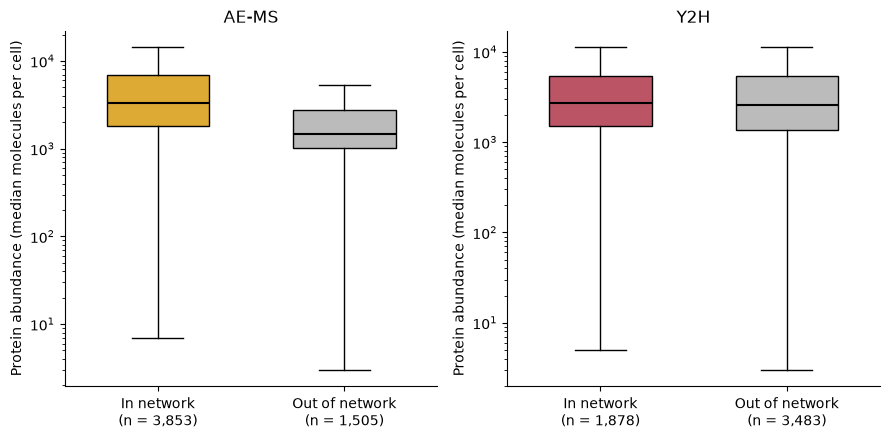


STATISTICAL RESULTS


,Network,Inside n,Inside median,Inside CI lower,Inside CI upper,Outside n,Outside median,Outside CI lower,Outside CI upper,Mann–Whitney U,p
0,AE-MS,3853,3314.0,3171.0,3441.0,1505,1467.0,1404.0,1532.0,4219305.0,2.511454e-148
1,Y2H,1878,2714.5,2589.0,2889.0,3483,2561.0,2486.0,2709.0,3345800.5,1.638787e-01


In [4]:
BOOTSTRAPS = 1_000_000
ABUNDANCE_COLUMN = "mean_molecules_per_cell"

NETWORKS = {
    "AE-MS": {
        "inside": Path(
            "../../18-finalize/processed-data/"
            "20260210-s288c-ANnnotated-Yeast-Interactome.pkl"
        ),
        "outside": Path("processed-data/missing-from-ae-ms-s288c.pkl"),
        "color": "#DDAA33",
    },
    "Y2H": {
        "inside": Path(
            "../../17-meltome-atlas/processed-data/"
            "y2h-test-s288c-step17.pkl"
        ),
        "outside": Path("processed-data/missing-from-y2h-s288c.pkl"),
        "color": "#BB5566",
    },
}


def load_nodes(path):
    df = pd.read_pickle(path).copy()

    if not df.columns.is_unique:
        raise ValueError(f"{path}: duplicate column names")

    required = {"node", ABUNDANCE_COLUMN}
    if not required.issubset(df.columns):
        raise ValueError(
            f"{path}: missing columns {sorted(required - set(df.columns))}"
        )

    df["node"] = df["node"].astype("string").str.strip()

    if df["node"].isna().any() or df["node"].eq("").any():
        raise ValueError(f"{path}: missing or blank node identifiers")

    duplicates = df.loc[
        df["node"].duplicated(keep=False), "node"
    ].unique()

    if len(duplicates):
        raise ValueError(
            f"{path}: duplicate node identifiers. "
            f"Examples: {duplicates[:10].tolist()}"
        )

    return df


def extract_abundances(df, network, group):
    values = pd.to_numeric(df[ABUNDANCE_COLUMN], errors="coerce")
    valid = values.notna() & np.isfinite(values)

    result = pd.DataFrame({
        "node": df.loc[valid, "node"],
        "Median molecules per cell": values.loc[valid],
    }).reset_index(drop=True)

    if result.empty:
        raise ValueError(f"{network}, {group}: no usable abundance measurements")

    if (result["Median molecules per cell"] <= 0).any():
        raise ValueError(
            f"{network}, {group}: nonpositive abundance values found; "
            "check before log plotting."
        )

    counts = {
        "Network": network,
        "Group": group,
        "Input nodes": len(df),
        "Missing/invalid abundance": int((~valid).sum()),
        "Usable abundance": len(result),
    }

    return result, counts


abundance_groups = {}
coverage_rows = []
statistics_rows = []

# Load and validate both comparisons before bootstrapping.
for network, settings in NETWORKS.items():
    inside_df = load_nodes(settings["inside"])
    outside_df = load_nodes(settings["outside"])

    overlap = set(inside_df["node"]) & set(outside_df["node"])

    if overlap:
        raise ValueError(
            f"{network}: inside/outside files share {len(overlap):,} "
            f"node identifiers. Examples: {sorted(overlap)[:10]}"
        )

    inside_data, inside_counts = extract_abundances(
        inside_df, network, "Inside"
    )
    outside_data, outside_counts = extract_abundances(
        outside_df, network, "Outside"
    )

    abundance_groups[network] = {
        "inside": inside_data,
        "outside": outside_data,
    }
    coverage_rows.extend([inside_counts, outside_counts])

coverage_summary = pd.DataFrame(coverage_rows)

print("ANNOTATION COVERAGE")
display(coverage_summary)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))

for ax, (network, settings) in zip(axes, NETWORKS.items()):
    inside = abundance_groups[network]["inside"]["Median molecules per cell"]
    outside = abundance_groups[network]["outside"]["Median molecules per cell"]

    # Bootstrap medians on the original abundance scale.
    m1, lo1, hi1 = bootstrap_ci_median(
        inside, B=BOOTSTRAPS, ci=95, random_state=27
    )
    m2, lo2, hi2 = bootstrap_ci_median(
        outside, B=BOOTSTRAPS, ci=95, random_state=27
    )

    # Two-sided rank-based comparison, not specifically a test of medians.
    u, p_value = mannwhitneyu(
        inside, outside, alternative="two-sided"
    )

    print(f"\n{network}, inside versus outside")
    print(
        f"Inside : median={m1:.2f}, "
        f"95% CI=({lo1:.2f}, {hi1:.2f}), n={len(inside):,}"
    )
    print(
        f"Outside: median={m2:.2f}, "
        f"95% CI=({lo2:.2f}, {hi2:.2f}), n={len(outside):,}"
    )
    print(f"U = {u:.2f}, p = {p_value:.4g}")

    statistics_rows.append({
        "Network": network,
        "Inside n": len(inside),
        "Inside median": m1,
        "Inside CI lower": lo1,
        "Inside CI upper": hi1,
        "Outside n": len(outside),
        "Outside median": m2,
        "Outside CI lower": lo2,
        "Outside CI upper": hi2,
        "Mann–Whitney U": u,
        "p": p_value,
    })

    boxes = ax.boxplot(
        [inside, outside],
        positions=[1, 2],
        widths=0.55,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.5},
    )

    for box, color in zip(
        boxes["boxes"], [settings["color"], "#BBBBBB"]
    ):
        box.set_facecolor(color)

    ax.set_xticks([1, 2])
    ax.set_xticklabels([
        f"In network\n(n = {len(inside):,})",
        f"Out of network\n(n = {len(outside):,})",
    ])
    ax.set_yscale("log")
    ax.set_ylabel("Protein abundance (median molecules per cell)")
    ax.set_title(network)
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()

statistics_summary = pd.DataFrame(statistics_rows)

print("\nSTATISTICAL RESULTS")
display(statistics_summary)

## Half-life

Half-life measurement coverage:


,Network,Group,Input nodes,Missing/invalid half-life,Usable half-life
0,AE-MS,inside,3927,1217,2710
1,AE-MS,outside,2111,1709,402
2,Y2H,inside,2018,839,1179
3,Y2H,outside,4079,2165,1914



AE-MS: bootstrapping median half-lives...


Bootstrapping medians: 100%|█████████████████████████████████████████| 1000000/1000000 [00:17<00:00, 56089.63it/s]

AE-MS, inside versus outside
Inside:  median=129.60 min, 95% CI=(127.20, 132.60), n=2,710
Outside: median=141.00 min, 95% CI=(133.80, 148.20), n=402
U = 472934.00, p = 1.959e-05

Y2H: bootstrapping median half-lives...



Bootstrapping medians: 100%|█████████████████████████████████████████| 1000000/1000000 [00:34<00:00, 29264.01it/s]


Y2H, inside versus outside
Inside:  median=135.00 min, 95% CI=(131.40, 138.00), n=1,179
Outside: median=128.40 min, 95% CI=(125.70, 132.00), n=1,914
U = 1196519.50, p = 0.004683


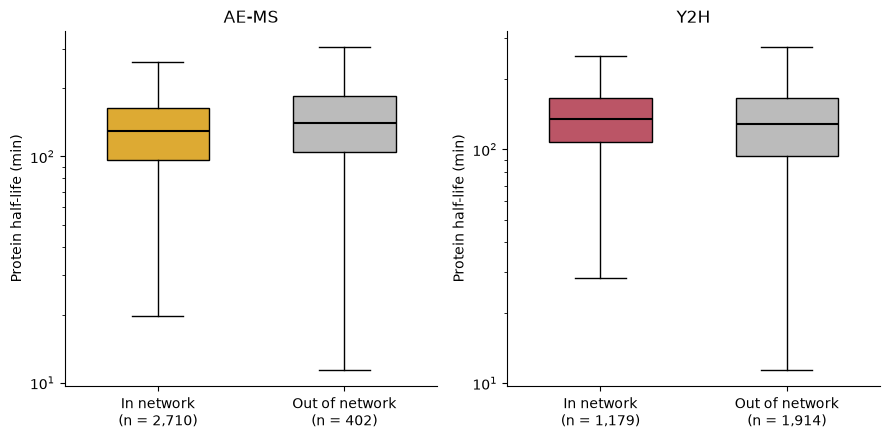

,Network,Inside n,Inside median (min),Inside CI lower,Inside CI upper,Outside n,Outside median (min),Outside CI lower,Outside CI upper,Mann–Whitney U,p-value
0,AE-MS,2710,129.6,127.2,132.6,402,141.0,133.8,148.2,472934.0,0.000020
1,Y2H,1179,135.0,131.4,138.0,1914,128.4,125.7,132.0,1196519.5,0.004683


In [5]:
HALFLIFE_COLUMN = "Villen_halflife_min"
BOOTSTRAPS = 1_000_000

NETWORKS = {
    "AE-MS": {
        "inside": Path(
            "../../18-finalize/processed-data/"
            "20260210-s288c-ANnnotated-Yeast-Interactome.pkl"
        ),
        "outside": Path("processed-data/missing-from-ae-ms-s288c.pkl"),
        "color": "#DDAA33",
    },
    "Y2H": {
        "inside": Path(
            "../../17-meltome-atlas/processed-data/"
            "y2h-test-s288c-step17.pkl"
        ),
        "outside": Path("processed-data/missing-from-y2h-s288c.pkl"),
        "color": "#BB5566",
    },
}


def load_halflife_nodes(path):
    """Read a node table and validate identifiers and required columns."""
    df = pd.read_pickle(path).copy()

    if not df.columns.is_unique:
        raise ValueError(f"{path}: duplicate column names")

    required = {"node", HALFLIFE_COLUMN}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path}: missing columns {sorted(missing)}")

    df["node"] = df["node"].astype("string").str.strip()

    if df["node"].isna().any() or df["node"].eq("").any():
        raise ValueError(f"{path}: null or blank node identifiers")

    duplicates = df.loc[df["node"].duplicated(keep=False), "node"].unique()
    if len(duplicates):
        raise ValueError(
            f"{path}: duplicate node identifiers: {duplicates[:10].tolist()}"
        )

    return df


def extract_halflives(df, network, group):
    """Retain finite half-life measurements; report missing measurements."""
    values = pd.to_numeric(df[HALFLIFE_COLUMN], errors="coerce")
    valid = values.notna() & np.isfinite(values)

    measurements = df.loc[valid, ["node"]].copy()
    measurements[HALFLIFE_COLUMN] = values.loc[valid]
    measurements = measurements.reset_index(drop=True)

    if measurements.empty:
        raise ValueError(f"{network}, {group}: no usable half-life measurements")

    nonpositive = measurements[HALFLIFE_COLUMN].le(0)
    if nonpositive.any():
        examples = measurements.loc[nonpositive, "node"].head(10).tolist()
        raise ValueError(
            f"{network}, {group}: {nonpositive.sum():,} nonpositive half-lives. "
            f"Check before log plotting. Examples: {examples}"
        )

    coverage = {
        "Network": network,
        "Group": group,
        "Input nodes": len(df),
        "Missing/invalid half-life": int((~valid).sum()),
        "Usable half-life": len(measurements),
    }

    return measurements, coverage


# Load and validate all groups before starting the bootstrap calculations.
halflife_groups = {}
coverage_rows = []

for network, settings in NETWORKS.items():
    inside_nodes = load_halflife_nodes(settings["inside"])
    outside_nodes = load_halflife_nodes(settings["outside"])

    overlap = set(inside_nodes["node"]) & set(outside_nodes["node"])
    if overlap:
        raise ValueError(
            f"{network}: {len(overlap):,} node identifiers occur in both groups. "
            f"Examples: {sorted(overlap)[:10]}"
        )

    halflife_groups[network] = {}

    for group, nodes in (
        ("inside", inside_nodes),
        ("outside", outside_nodes),
    ):
        measurements, coverage = extract_halflives(nodes, network, group)
        halflife_groups[network][group] = measurements
        coverage_rows.append(coverage)

halflife_coverage = pd.DataFrame(coverage_rows)

print("Half-life measurement coverage:")
display(halflife_coverage)


# Bootstrap medians, compare distributions, and plot.
statistics_rows = []
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))

for ax, (network, settings) in zip(axes, NETWORKS.items()):
    inside = halflife_groups[network]["inside"][HALFLIFE_COLUMN]
    outside = halflife_groups[network]["outside"][HALFLIFE_COLUMN]

    print(f"\n{network}: bootstrapping median half-lives...", flush=True)

    m1, lo1, hi1 = bootstrap_ci_median(
        inside, B=BOOTSTRAPS, ci=95, random_state=27
    )
    m2, lo2, hi2 = bootstrap_ci_median(
        outside, B=BOOTSTRAPS, ci=95, random_state=27
    )

    # Rank-based comparison; not specifically a test of median differences.
    u, p = mannwhitneyu(inside, outside, alternative="two-sided")

    print(f"{network}, inside versus outside")
    print(
        f"Inside:  median={m1:.2f} min, "
        f"95% CI=({lo1:.2f}, {hi1:.2f}), n={len(inside):,}"
    )
    print(
        f"Outside: median={m2:.2f} min, "
        f"95% CI=({lo2:.2f}, {hi2:.2f}), n={len(outside):,}"
    )
    print(f"U = {u:.2f}, p = {p:.4g}")

    statistics_rows.append({
        "Network": network,
        "Inside n": len(inside),
        "Inside median (min)": m1,
        "Inside CI lower": lo1,
        "Inside CI upper": hi1,
        "Outside n": len(outside),
        "Outside median (min)": m2,
        "Outside CI lower": lo2,
        "Outside CI upper": hi2,
        "Mann–Whitney U": u,
        "p-value": p,
    })

    boxes = ax.boxplot(
        [inside, outside],
        positions=[1, 2],
        widths=0.55,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.5},
    )

    for box, color in zip(
        boxes["boxes"], [settings["color"], "#BBBBBB"]
    ):
        box.set_facecolor(color)

    ax.set_xticks([1, 2])
    ax.set_xticklabels([
        f"In network\n(n = {len(inside):,})",
        f"Out of network\n(n = {len(outside):,})",
    ])
    ax.set_yscale("log")
    ax.set_ylabel("Protein half-life (min)")
    ax.set_title(network)
    ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
plt.show()

halflife_statistics = pd.DataFrame(statistics_rows)
display(halflife_statistics)

## Folded-state stability

Stability eligibility filtering:


,Network,Group,Input nodes,Dropped: pLDDT <70 or missing/invalid,Remaining after pLDDT,Dropped: TM/SP+TM/BETA after pLDDT,Remaining for stability comparisons
0,AE-MS,inside,3927,963,2964,436,2528
1,AE-MS,outside,2111,829,1282,381,901
2,Y2H,inside,2018,592,1426,158,1268
3,Y2H,outside,4079,1255,2824,660,2164



Stability measurement coverage after eligibility filtering:


,Metric,Network,Group,Nodes after eligibility filtering,Missing/invalid metric values,Usable metric values
0,Ghosh-Dill-dG,AE-MS,inside,2528,0,2528
1,Ghosh-Dill-dG,AE-MS,outside,901,0,901
2,Ghosh-Dill-dG,Y2H,inside,1268,0,1268
3,Ghosh-Dill-dG,Y2H,outside,2164,0,2164
4,cagiada-dG,AE-MS,inside,2528,0,2528
5,cagiada-dG,AE-MS,outside,901,0,901
6,cagiada-dG,Y2H,inside,1268,0,1268
7,cagiada-dG,Y2H,outside,2164,0,2164
8,Rosetta_best_total_score,AE-MS,inside,2528,0,2528
9,Rosetta_best_total_score,AE-MS,outside,901,0,901



Ghosh-Dill-dG — AE-MS: bootstrapping medians...


Bootstrapping medians: 100%|█████████████████████████████████████████| 1000000/1000000 [00:23<00:00, 43227.83it/s]


Inside:  median=-10.550, 95% CI=(-10.777, -10.341), n=2,528
Outside: median=-9.451, 95% CI=(-9.696, -9.103), n=901
U = 921154.50, p = 1.434e-17

Ghosh-Dill-dG — Y2H: bootstrapping medians...


Bootstrapping medians: 100%|█████████████████████████████████████████| 1000000/1000000 [00:36<00:00, 27170.23it/s]


Inside:  median=-9.887, 95% CI=(-10.140, -9.643), n=1,268
Outside: median=-10.393, 95% CI=(-10.655, -10.132), n=2,164
U = 1438608.00, p = 0.0174


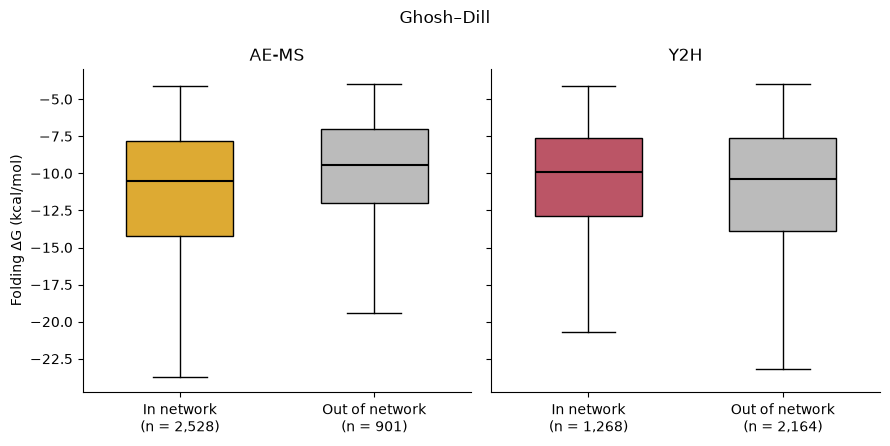


cagiada-dG — AE-MS: bootstrapping medians...


Bootstrapping medians: 100%|█████████████████████████████████████████| 1000000/1000000 [00:23<00:00, 43045.28it/s]

Inside:  median=19.511, 95% CI=(18.988, 20.090), n=2,528
Outside: median=17.613, 95% CI=(16.681, 18.404), n=901
U = 1275585.00, p = 8.401e-08

cagiada-dG — Y2H: bootstrapping medians...



Bootstrapping medians: 100%|█████████████████████████████████████████| 1000000/1000000 [00:37<00:00, 26906.61it/s]


Inside:  median=18.182, 95% CI=(17.279, 18.990), n=1,268
Outside: median=19.557, 95% CI=(18.768, 20.108), n=2,164
U = 1286424.00, p = 0.002262


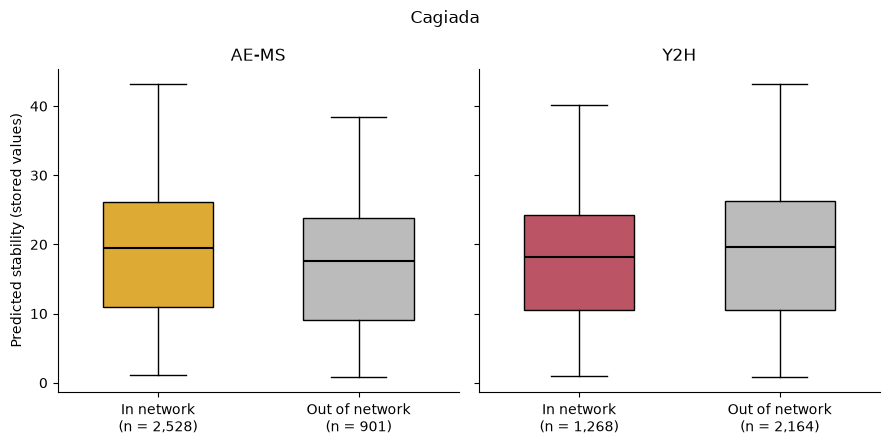


Rosetta_best_total_score — AE-MS: bootstrapping medians...


Bootstrapping medians: 100%|█████████████████████████████████████████| 1000000/1000000 [00:23<00:00, 43190.74it/s]


Inside:  median=-1088.957, 95% CI=(-1121.294, -1055.059), n=2,528
Outside: median=-951.410, 95% CI=(-1014.803, -902.073), n=901
U = 975327.00, p = 1.462e-10

Rosetta_best_total_score — Y2H: bootstrapping medians...


Bootstrapping medians: 100%|█████████████████████████████████████████| 1000000/1000000 [00:36<00:00, 27198.94it/s]


Inside:  median=-1002.038, 95% CI=(-1056.399, -971.791), n=1,268
Outside: median=-1086.570, 95% CI=(-1124.834, -1043.046), n=2,164
U = 1442096.50, p = 0.01233


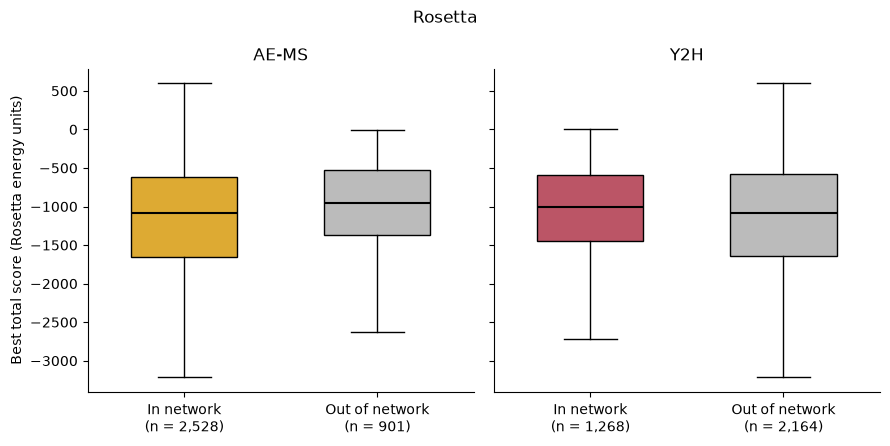


Stability comparison statistics (unadjusted p-values):


,Metric,Network,Inside n,Inside median,Inside CI lower,Inside CI upper,Outside n,Outside median,Outside CI lower,Outside CI upper,Mann–Whitney U,p-value
0,Ghosh-Dill-dG,AE-MS,2528,-10.550116,-10.776846,-10.340828,901,-9.451351,-9.695521,-9.102536,921154.5,1.433802e-17
1,Ghosh-Dill-dG,Y2H,1268,-9.887369,-10.140259,-9.643199,2164,-10.393150,-10.654761,-10.131539,1438608.0,1.739808e-02
2,cagiada-dG,AE-MS,2528,19.510543,18.988038,20.089683,901,17.612556,16.680664,18.404042,1275585.0,8.401299e-08
3,cagiada-dG,Y2H,1268,18.182222,17.279409,18.989939,2164,19.556796,18.767818,20.107699,1286424.0,2.262143e-03
4,Rosetta_best_total_score,AE-MS,2528,-1088.956500,-1121.294000,-1055.059000,901,-951.410000,-1014.803000,-902.073000,975327.0,1.462355e-10
5,Rosetta_best_total_score,Y2H,1268,-1002.038500,-1056.399500,-971.790500,2164,-1086.569500,-1124.834000,-1043.046000,1442096.5,1.232528e-02


In [6]:
BOOTSTRAPS = 1_000_000
PLDDT_THRESHOLD = 70
EXCLUDED_CLASSES = ["TM", "SP+TM", "BETA"]

METRICS = {
    "Ghosh-Dill-dG": {
        "title": "Ghosh–Dill",
        "ylabel": "Folding ΔG (kcal/mol)",
    },
    "cagiada-dG": {
        "title": "Cagiada",
        "ylabel": "Predicted stability (stored values)",
    },
    "Rosetta_best_total_score": {
        "title": "Rosetta",
        "ylabel": "Best total score (Rosetta energy units)",
    },
}

NETWORKS = {
    "AE-MS": {
        "inside": Path(
            "../../18-finalize/processed-data/"
            "20260210-s288c-ANnnotated-Yeast-Interactome.pkl"
        ),
        "outside": Path("processed-data/missing-from-ae-ms-s288c.pkl"),
        "color": "#DDAA33",
    },
    "Y2H": {
        "inside": Path(
            "../../17-meltome-atlas/processed-data/"
            "y2h-test-s288c-step17.pkl"
        ),
        "outside": Path("processed-data/missing-from-y2h-s288c.pkl"),
        "color": "#BB5566",
    },
}


def load_stability_nodes(path):
    """Load a node table and validate identifiers and required columns."""
    df = pd.read_pickle(path).copy()

    if not df.columns.is_unique:
        raise ValueError(f"{path}: duplicate column names")

    required = {"node", "mean_plddt", "DeepTMHMM_class", *METRICS}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path}: missing columns {sorted(missing)}")

    df["node"] = df["node"].astype("string").str.strip()

    if df["node"].isna().any() or df["node"].eq("").any():
        raise ValueError(f"{path}: null or blank node identifiers")

    duplicates = df.loc[df["node"].duplicated(keep=False), "node"].unique()
    if len(duplicates):
        raise ValueError(
            f"{path}: duplicate node identifiers: {duplicates[:10].tolist()}"
        )

    return df


def filter_stability_nodes(nodes, network, group):
    """Apply confidence and membrane-class filters, with sequential counts."""
    plddt = pd.to_numeric(nodes["mean_plddt"], errors="coerce")

    confidence_mask = plddt.ge(PLDDT_THRESHOLD).fillna(False)
    excluded_class_mask = nodes["DeepTMHMM_class"].isin(EXCLUDED_CLASSES)

    filtered = nodes.loc[
        confidence_mask & ~excluded_class_mask
    ].copy()

    summary = {
        "Network": network,
        "Group": group,
        "Input nodes": len(nodes),
        "Dropped: pLDDT <70 or missing/invalid": int(
            (~confidence_mask).sum()
        ),
        "Remaining after pLDDT": int(confidence_mask.sum()),
        "Dropped: TM/SP+TM/BETA after pLDDT": int(
            (confidence_mask & excluded_class_mask).sum()
        ),
        "Remaining for stability comparisons": len(filtered),
    }

    return filtered, summary


def extract_stability_values(df, metric, network, group):
    """Retain finite numeric values, including negative values and zero."""
    values = pd.to_numeric(df[metric], errors="coerce")
    valid = (values.notna() & np.isfinite(values)).fillna(False)

    measurements = df.loc[valid, ["node"]].copy()
    measurements[metric] = values.loc[valid]
    measurements = measurements.reset_index(drop=True)

    coverage = {
        "Metric": metric,
        "Network": network,
        "Group": group,
        "Nodes after eligibility filtering": len(df),
        "Missing/invalid metric values": int((~valid).sum()),
        "Usable metric values": len(measurements),
    }

    return measurements, coverage


# Load each file once, check membership, and apply eligibility filters.
node_tables = {}
filter_rows = []

for network, settings in NETWORKS.items():
    inside_nodes = load_stability_nodes(settings["inside"])
    outside_nodes = load_stability_nodes(settings["outside"])

    # Check membership before filtering.
    overlap = set(inside_nodes["node"]) & set(outside_nodes["node"])
    if overlap:
        raise ValueError(
            f"{network}: {len(overlap):,} node identifiers occur in both groups. "
            f"Examples: {sorted(overlap)[:10]}"
        )

    node_tables[network] = {}

    for group, nodes in (
        ("inside", inside_nodes),
        ("outside", outside_nodes),
    ):
        filtered_nodes, summary = filter_stability_nodes(
            nodes, network, group
        )
        node_tables[network][group] = filtered_nodes
        filter_rows.append(summary)

stability_filter_summary = pd.DataFrame(filter_rows)

print("Stability eligibility filtering:")
display(stability_filter_summary)


# Prepare each metric independently from the filtered tables.
stability_groups = {}
coverage_rows = []
empty_groups = []

for metric in METRICS:
    stability_groups[metric] = {}

    for network in NETWORKS:
        stability_groups[metric][network] = {}

        for group in ("inside", "outside"):
            measurements, coverage = extract_stability_values(
                node_tables[network][group], metric, network, group
            )

            stability_groups[metric][network][group] = measurements
            coverage_rows.append(coverage)

            if measurements.empty:
                empty_groups.append(f"{metric}: {network}, {group}")

stability_coverage = pd.DataFrame(coverage_rows)

print("\nStability measurement coverage after eligibility filtering:")
display(stability_coverage)

if empty_groups:
    raise ValueError(
        "No usable measurements in these groups:\n" + "\n".join(empty_groups)
    )


# Bootstrap medians, compare distributions, and plot.
# One figure per metric, with AE-MS and Y2H panels.
statistics_rows = []
stability_figures = {}

for metric, metric_settings in METRICS.items():
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), sharey=True)
    stability_figures[metric] = fig

    for ax, (network, network_settings) in zip(axes, NETWORKS.items()):
        inside = stability_groups[metric][network]["inside"][metric]
        outside = stability_groups[metric][network]["outside"][metric]

        print(
            f"\n{metric} — {network}: bootstrapping medians...",
            flush=True,
        )

        m1, lo1, hi1 = bootstrap_ci_median(
            inside, B=BOOTSTRAPS, ci=95, random_state=27
        )
        m2, lo2, hi2 = bootstrap_ci_median(
            outside, B=BOOTSTRAPS, ci=95, random_state=27
        )

        # Rank-based comparison; not specifically a test of median differences.
        u, p = mannwhitneyu(inside, outside, alternative="two-sided")

        print(
            f"Inside:  median={m1:.3f}, "
            f"95% CI=({lo1:.3f}, {hi1:.3f}), n={len(inside):,}"
        )
        print(
            f"Outside: median={m2:.3f}, "
            f"95% CI=({lo2:.3f}, {hi2:.3f}), n={len(outside):,}"
        )
        print(f"U = {u:.2f}, p = {p:.4g}")

        statistics_rows.append({
            "Metric": metric,
            "Network": network,
            "Inside n": len(inside),
            "Inside median": m1,
            "Inside CI lower": lo1,
            "Inside CI upper": hi1,
            "Outside n": len(outside),
            "Outside median": m2,
            "Outside CI lower": lo2,
            "Outside CI upper": hi2,
            "Mann–Whitney U": u,
            "p-value": p,
        })

        boxes = ax.boxplot(
            [inside, outside],
            positions=[1, 2],
            widths=0.55,
            patch_artist=True,
            showfliers=False,
            medianprops={"color": "black", "linewidth": 1.5},
        )

        for box, color in zip(
            boxes["boxes"], [network_settings["color"], "#BBBBBB"]
        ):
            box.set_facecolor(color)

        ax.set_xticks([1, 2])
        ax.set_xticklabels([
            f"In network\n(n = {len(inside):,})",
            f"Out of network\n(n = {len(outside):,})",
        ])

        # Stability values may be negative or zero.
        ax.set_yscale("linear")
        ax.set_title(network)
        ax.spines[["top", "right"]].set_visible(False)

    axes[0].set_ylabel(metric_settings["ylabel"])
    fig.suptitle(metric_settings["title"])
    fig.tight_layout()
    plt.show()

stability_statistics = pd.DataFrame(statistics_rows)

print("\nStability comparison statistics (unadjusted p-values):")
display(stability_statistics)

## Melting point

Meltome filtering and measurement coverage (sequential counts):


,Network,Group,Input nodes,Dropped: TM/SP+TM/BETA,Remaining after class filter,Dropped: R² ≤0.9 or missing/invalid,Remaining after R² filter,Dropped: missing/invalid melting point,Usable melting points
0,AE-MS,inside,3927,519,3408,1744,1664,87,1577
1,AE-MS,outside,2111,476,1635,1361,274,17,257
2,Y2H,inside,2018,203,1815,1043,772,46,726
3,Y2H,outside,4079,793,3286,2119,1167,58,1109



Meltome — AE-MS: bootstrapping median melting temperatures...


Bootstrapping medians: 100%|█████████████████████████████████████████| 1000000/1000000 [00:16<00:00, 61072.54it/s]

Inside:  median=49.36 °C, 95% CI=(49.14, 49.60), n=1,577
Outside: median=50.29 °C, 95% CI=(49.85, 50.89), n=257
U = 171245.50, p = 6.652e-05

Meltome — Y2H: bootstrapping median melting temperatures...



Bootstrapping medians: 100%|█████████████████████████████████████████| 1000000/1000000 [00:25<00:00, 38827.79it/s]


Inside:  median=49.96 °C, 95% CI=(49.73, 50.16), n=726
Outside: median=49.13 °C, 95% CI=(48.75, 49.40), n=1,109
U = 457053.50, p = 9.148e-07


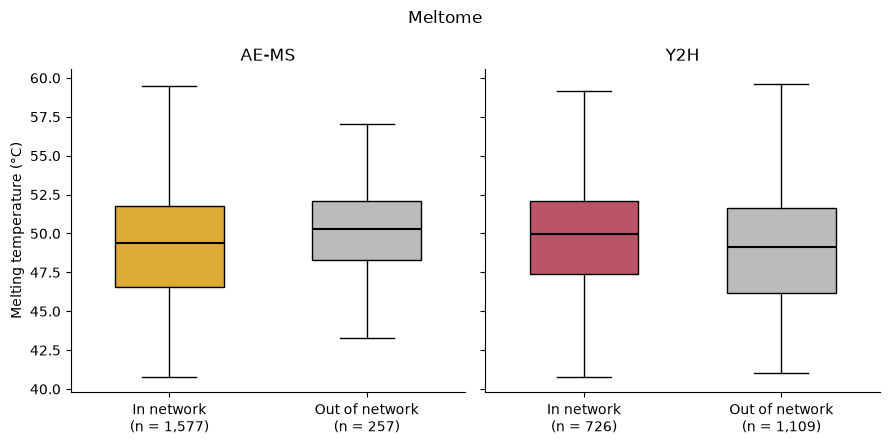


Meltome comparison statistics (unadjusted p-values):


,Network,Inside n,Inside median (°C),Inside CI lower,Inside CI upper,Outside n,Outside median (°C),Outside CI lower,Outside CI upper,Mann–Whitney U,p-value
0,AE-MS,1577,49.36,49.14,49.60,257,50.29,49.85,50.89,171245.5,6.651840e-05
1,Y2H,726,49.96,49.73,50.16,1109,49.13,48.75,49.40,457053.5,9.147600e-07


In [8]:
BOOTSTRAPS = 1_000_000
METRIC = "meltome-melting-point"
EXCLUDED_CLASSES = ["TM", "SP+TM", "BETA"]

NETWORKS = {
    "AE-MS": {
        "inside": Path(
            "../../18-finalize/processed-data/"
            "20260210-s288c-ANnnotated-Yeast-Interactome.pkl"
        ),
        "outside": Path("processed-data/missing-from-ae-ms-s288c.pkl"),
        "color": "#DDAA33",
    },
    "Y2H": {
        "inside": Path(
            "../../17-meltome-atlas/processed-data/"
            "y2h-test-s288c-step17.pkl"
        ),
        "outside": Path("processed-data/missing-from-y2h-s288c.pkl"),
        "color": "#BB5566",
    },
}


def load_meltome_nodes(path):
    """Load a table and validate identifiers and required columns."""
    df = pd.read_pickle(path).copy()

    if not df.columns.is_unique:
        raise ValueError(f"{path}: duplicate column names")

    required = {"node", "DeepTMHMM_class", "meltome-fit-R2", METRIC}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path}: missing columns {sorted(missing)}")

    df["node"] = df["node"].astype("string").str.strip()

    if df["node"].isna().any() or df["node"].eq("").any():
        raise ValueError(f"{path}: null or blank node identifiers")

    duplicates = df.loc[df["node"].duplicated(keep=False), "node"].unique()
    if len(duplicates):
        raise ValueError(
            f"{path}: duplicate node identifiers: {duplicates[:10].tolist()}"
        )

    return df


def filter_meltome_nodes(nodes, network, group):
    """Filter by membrane class, fit quality, and available temperature."""
    fit_r2 = pd.to_numeric(nodes["meltome-fit-R2"], errors="coerce")
    melting_point = pd.to_numeric(nodes[METRIC], errors="coerce")

    after_class = ~nodes["DeepTMHMM_class"].isin(EXCLUDED_CLASSES)

    # Require a finite fit R² strictly greater than 0.9.
    good_fit = (
        fit_r2.notna()
        & np.isfinite(fit_r2)
        & fit_r2.gt(0.9)
    ).fillna(False)
    after_fit = after_class & good_fit

    # Require a finite melting temperature.
    finite_temperature = (
        melting_point.notna() & np.isfinite(melting_point)
    ).fillna(False)
    usable = after_fit & finite_temperature

    measurements = nodes.loc[usable, ["node"]].copy()
    measurements[METRIC] = melting_point.loc[usable]
    measurements = measurements.reset_index(drop=True)

    summary = {
        "Network": network,
        "Group": group,
        "Input nodes": len(nodes),
        "Dropped: TM/SP+TM/BETA": int((~after_class).sum()),
        "Remaining after class filter": int(after_class.sum()),
        "Dropped: R² ≤0.9 or missing/invalid": int(
            (after_class & ~after_fit).sum()
        ),
        "Remaining after R² filter": int(after_fit.sum()),
        "Dropped: missing/invalid melting point": int(
            (after_fit & ~usable).sum()
        ),
        "Usable melting points": len(measurements),
    }

    return measurements, summary


# Load all four groups and apply filters before starting calculations.
meltome_groups = {}
filter_rows = []
empty_groups = []

for network, settings in NETWORKS.items():
    inside_nodes = load_meltome_nodes(settings["inside"])
    outside_nodes = load_meltome_nodes(settings["outside"])

    # Membership is defined by the input pickle files.
    overlap = set(inside_nodes["node"]) & set(outside_nodes["node"])
    if overlap:
        raise ValueError(
            f"{network}: {len(overlap):,} node identifiers occur in both groups. "
            f"Examples: {sorted(overlap)[:10]}"
        )

    meltome_groups[network] = {}

    for group, nodes in (
        ("inside", inside_nodes),
        ("outside", outside_nodes),
    ):
        measurements, summary = filter_meltome_nodes(
            nodes, network, group
        )
        meltome_groups[network][group] = measurements
        filter_rows.append(summary)

        if measurements.empty:
            empty_groups.append(f"{network}, {group}")

meltome_filter_summary = pd.DataFrame(filter_rows)

print("Meltome filtering and measurement coverage (sequential counts):")
display(meltome_filter_summary)

if empty_groups:
    raise ValueError(
        "No usable melting points in these groups:\n"
        + "\n".join(empty_groups)
    )


# Bootstrap medians, compare distributions, and plot.
statistics_rows = []
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), sharey=True)

for ax, (network, settings) in zip(axes, NETWORKS.items()):
    inside = meltome_groups[network]["inside"][METRIC]
    outside = meltome_groups[network]["outside"][METRIC]

    print(
        f"\nMeltome — {network}: bootstrapping median melting temperatures...",
        flush=True,
    )

    m1, lo1, hi1 = bootstrap_ci_median(
        inside, B=BOOTSTRAPS, ci=95, random_state=27
    )
    m2, lo2, hi2 = bootstrap_ci_median(
        outside, B=BOOTSTRAPS, ci=95, random_state=27
    )

    # Rank-based comparison; not specifically a test of median differences.
    u, p = mannwhitneyu(inside, outside, alternative="two-sided")

    print(
        f"Inside:  median={m1:.2f} °C, "
        f"95% CI=({lo1:.2f}, {hi1:.2f}), n={len(inside):,}"
    )
    print(
        f"Outside: median={m2:.2f} °C, "
        f"95% CI=({lo2:.2f}, {hi2:.2f}), n={len(outside):,}"
    )
    print(f"U = {u:.2f}, p = {p:.4g}")

    statistics_rows.append({
        "Network": network,
        "Inside n": len(inside),
        "Inside median (°C)": m1,
        "Inside CI lower": lo1,
        "Inside CI upper": hi1,
        "Outside n": len(outside),
        "Outside median (°C)": m2,
        "Outside CI lower": lo2,
        "Outside CI upper": hi2,
        "Mann–Whitney U": u,
        "p-value": p,
    })

    boxes = ax.boxplot(
        [inside, outside],
        positions=[1, 2],
        widths=0.55,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.5},
    )

    for box, color in zip(
        boxes["boxes"], [settings["color"], "#BBBBBB"]
    ):
        box.set_facecolor(color)

    ax.set_xticks([1, 2])
    ax.set_xticklabels([
        f"In network\n(n = {len(inside):,})",
        f"Out of network\n(n = {len(outside):,})",
    ])
    ax.set_yscale("linear")
    ax.set_title(network)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Melting temperature (°C)")
fig.suptitle("Meltome")
fig.tight_layout()
plt.show()

meltome_statistics = pd.DataFrame(statistics_rows)

print("\nMeltome comparison statistics (unadjusted p-values):")
display(meltome_statistics)